In [11]:
# === BOILERPLATE: locate repo & sessions ===
import sys, pickle
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal
from tqdm.auto import tqdm
from joblib import Parallel, delayed
import gc

# Configure Plotting
plt.style.use('seaborn-v0_8-whitegrid')

# Repo Discovery
start = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()
for p in (start, *start.parents):
    if p.name == "syllable_generation":
        REPO_ROOT = p
        break
else:
    REPO_ROOT = Path("/home/fsp585/Desktop/FiberphotometryCode/syllable_generation")

PKG_PARENT = REPO_ROOT.parent
if str(PKG_PARENT) not in sys.path:
    sys.path.insert(0, str(PKG_PARENT))

# Load Sessions
PKL = REPO_ROOT / "loaders" / "jonathan_ifdn_sessions_w_all_data.pkl"
if not PKL.exists():
    # Fallback logic (same as your existing notebooks)
    loaders_dir = REPO_ROOT / "loaders"
    candidates = list(loaders_dir.glob("*.pkl"))
    PKL = max(candidates, key=lambda p: p.stat().st_mtime)

print(f"Loading sessions from {PKL}...")
with PKL.open("rb") as f:
    sessions = pickle.load(f)

# Quick filter
sessions = [
    s for s in sessions
    if hasattr(s, "all_data_df") and isinstance(s.all_data_df, pd.DataFrame) and not s.all_data_df.empty
]
print(f"Usable sessions: {len(sessions)}")

Loading sessions from /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/jonathan_ifdn_sessions_w_sylls_datta.pkl...
Usable sessions: 19


In [12]:
import numpy as np
import pandas as pd
from scipy import signal

# === 1. Robust Syllable Onset Detector (with Glitch Filter) ===
def detect_syllable_onsets(
    df: pd.DataFrame, 
    fs: float = 80.0, 
    min_duration_s: float = 0.15 # 150ms minimum duration to ignore glitches
) -> np.ndarray:
    """
    Detects syllable changes, discarding bouts shorter than min_duration_s.
    """
    syl = df["syllable"].to_numpy()
    
    # 1. Find changes (0 at start, 1 where value changes)
    # We prepend a value to handle the first frame comparison
    is_change = np.concatenate(([1], syl[1:] != syl[:-1]))
    change_indices = np.flatnonzero(is_change)
    
    # 2. Calculate durations of each bout (in frames)
    # Diff between change indices gives the length of the segment
    run_lengths = np.diff(np.concatenate((change_indices, [len(syl)])))
    
    # 3. Filter: We only want onsets where the *new* bout is long enough
    min_frames = int(min_duration_s * fs)
    valid_mask = (run_lengths >= min_frames)
    
    # Map back to original indices
    valid_onsets = change_indices[valid_mask]
    
    # 4. Remove NaNs (if the syllable itself is NaN, it's not a behavior)
    if len(valid_onsets) > 0:
        valid_values = syl[valid_onsets]
        try:
             # Safe float conversion for nan check
             is_nan = np.isnan(valid_values.astype(float))
             valid_onsets = valid_onsets[~is_nan]
        except Exception:
            pass 
            
    return valid_onsets


# === 2. The Jitter Worker (Parallel Execution) ===
def _memmap_jitter_worker(
    npy_path: str,
    n_shuffles_per_job: int,
    rng_seed: int,
    fs: float,
    n_total_frames: int,
    n_events: int,
    # Jitter Config
    jitter_range_s: float = 2.0,
    analysis_window: tuple = (-1.5, 1.5),
):
    """
    Reads wide derivative matrix from disk and performs Jitter Shuffling.
    Slides the analysis window by a random offset within the wide buffer.
    """
    # Load memmap (Zero-Copy read)
    matrix = np.load(npy_path, mmap_mode='r')
    
    # Calculate key indices
    center_idx = n_total_frames // 2
    
    # Analysis window size in frames
    win_start_f = int(analysis_window[0] * fs)
    win_end_f   = int(analysis_window[1] * fs)
    win_len     = win_end_f - win_start_f
    
    # Max jitter shift
    jitter_max_f = int(jitter_range_s * fs)
    
    # Base start index (Time 0 aligned)
    base_start = center_idx + win_start_f
    
    rng = np.random.default_rng(rng_seed)
    shuffle_means = []
    
    for _ in range(n_shuffles_per_job):
        # Generate random jitter: integer [-J, +J]
        jitters = rng.integers(-jitter_max_f, jitter_max_f, size=n_events)
        
        # Calculate start indices
        starts = base_start + jitters
        
        # Safety clip to stay within the +/-10s buffer
        starts = np.clip(starts, 0, n_total_frames - win_len)
        
        # Vectorized Extraction (Fancy Indexing)
        # Create a grid of indices for all events at once
        col_idx = np.arange(win_len)[None, :] + starts[:, None]
        row_idx = np.arange(n_events)[:, None]
        
        # Extract chunk from disk -> RAM
        shuffled_chunk = matrix[row_idx, col_idx]
        
        # Compute mean across events for this shuffle iteration
        shuffle_means.append(np.nanmean(shuffled_chunk, axis=0))
        
    return np.array(shuffle_means)

In [13]:
# === 2. Helper Functions ===
FS = 80.0

def dlight_filter(arr: np.ndarray, fs=FS):
    """Apply 1Hz High-pass Bessel filter (Reference style)."""
    sos = signal.bessel(1, 1.0 / (fs / 2.0), btype="high", output="sos")
    # Fill NaNs with 0 for filtering, then restore
    mask = np.isnan(arr)
    if mask.all(): return arr
    arr_filled = np.nan_to_num(arr)
    filtered = signal.sosfiltfilt(sos, arr_filled)
    filtered[mask] = np.nan
    return filtered

def get_derivative_matrix_wide(sessions, genotype="WT", area="DMS"):
    """
    Extracts +/- 10s wide derivative windows.
    Derivative method: Forward Diff with 0.1s lag.
    """
    snippets_list = []
    
    # Wide extraction params
    pre_s, post_s = -10.0, 10.0
    pre_f = int(pre_s * FS)
    post_f = int(post_s * FS)
    
    # Derivative Lag: Reference uses 3 samples @ 30Hz (0.1s)
    diff_lag = int(0.1 * FS)  # ~8 frames @ 80Hz
    if diff_lag < 1: diff_lag = 1

    for sess in tqdm(sessions, desc=f"Extracting {area}"):
        # Filter Genotype
        g = (getattr(sess, "metadata", {}) or {}).get("genotype", "UNK")
        if g != genotype: continue
        
        # Find Signal Column (Prefer Datta)
        meta = sess.metadata
        signal_meta = meta.get("signal_meta", {}) or {}
        sig_key = None
        for key, info in signal_meta.items():
            if str(info.get("brain_reg", "")).lower() == area.lower():
                sig_key = key
                break
        
        if sig_key is None: continue
        
        col = f"{sig_key}_zscore_datta"
        if col not in sess.all_data_df.columns:
            continue

        df = sess.all_data_df
        
        # Onsets (Reuse your robust detection)
        # Assuming detect_syllable_onsets is defined in your notebook
        onsets = detect_syllable_onsets(df, min_duration_s=0.15)
        if len(onsets) == 0: continue
        
        # Data
        sig = df[col].to_numpy()
        n_frames = len(sig)
        
        # Valid Mask (bounds)
        valid_mask = (onsets + pre_f >= 0) & (onsets + post_f < n_frames)
        valid_onsets = onsets[valid_mask]
        if len(valid_onsets) == 0: continue
        
        # 1. Extract Raw Wide Snippets
        idx = valid_onsets[:, None] + np.arange(pre_f, post_f + 1)[None, :]
        raw_snippets = sig[idx]
        
        # 2. Filter (1Hz High Pass)
        filt_snippets = np.apply_along_axis(dlight_filter, 1, raw_snippets)
        
        # 3. Compute Derivative (Diff / dt)
        # x[t] - x[t - lag]
        deriv_snippets = (filt_snippets[:, diff_lag:] - filt_snippets[:, :-diff_lag]) / diff_lag
        
        snippets_list.append(deriv_snippets)
        
    if not snippets_list: return None
    return np.vstack(snippets_list)

In [14]:
import pickle

# === 3. The Orchestrator (With Caching) ===
def run_deriv_analysis_jitter(sessions, genotype, area, n_shuffles=1000, fs=80.0):
    print(f"--- Analysis: {genotype} {area} ---")
    
    # Define Cache Path
    if 'CACHE_DIR' not in globals(): 
        global CACHE_DIR
        CACHE_DIR = Path("./cache")
        CACHE_DIR.mkdir(exist_ok=True)
        
    stats_cache_file = CACHE_DIR / f"deriv_stats_{genotype}_{area}.pkl"
    stats = None
    
    # 1. Try Loading Cache
    if stats_cache_file.exists():
        print(f"Loading stats from cache: {stats_cache_file.name}")
        try:
            with open(stats_cache_file, "rb") as f:
                stats = pickle.load(f)
        except Exception as e:
            print(f"Cache corrupted ({e}), recomputing...")
            
    # 2. Compute if not cached
    if stats is None:
        # A. Extract Wide Matrix
        matrix = get_derivative_matrix_wide(sessions, genotype, area)
        if matrix is None:
            print("No data found.")
            return
            
        n_events, n_total_frames = matrix.shape
        print(f"Data Matrix: {n_events} events x {n_total_frames} timepoints")
        
        # B. Save to Memmap
        npy_path = CACHE_DIR / "temp_deriv_matrix.npy"
        if npy_path.exists(): npy_path.unlink()
        
        try:
            print(f"Saving memmap to {npy_path}...")
            np.save(npy_path, matrix.astype(np.float32))
            
            # C. Compute Observed
            print("Computing Observed...")
            center_idx = n_total_frames // 2
            win_start_f = int(-1.5 * fs)
            win_end_f   = int(1.5 * fs)
            
            obs_start = center_idx + win_start_f
            obs_end   = center_idx + win_end_f
            
            m = np.load(npy_path, mmap_mode='r')
            obs_chunk = m[:, obs_start:obs_end]
            
            obs_mean = np.nanmean(obs_chunk, axis=0)
            obs_sem  = np.nanstd(obs_chunk, axis=0) / np.sqrt(n_events)
            
            # D. Run Shuffles (Parallel Jitter)
            print(f"Running {n_shuffles} Shuffles...")
            n_jobs = 8
            shuffles_per_job = n_shuffles // n_jobs
            if n_shuffles % n_jobs != 0: shuffles_per_job += 1
            
            results = Parallel(n_jobs=n_jobs)(
                delayed(_memmap_jitter_worker)(
                    npy_path=npy_path,
                    n_shuffles_per_job=shuffles_per_job,
                    rng_seed=i,
                    fs=fs,
                    n_total_frames=n_total_frames,
                    n_events=n_events,
                    jitter_range_s=2.0, 
                    analysis_window=(-1.5, 1.5)
                )
                for i in tqdm(range(n_jobs), leave=False)
            )
            
            # E. Aggregate Stats
            all_shuffles = np.vstack(results)
            all_shuffles = all_shuffles[:n_shuffles]
            
            shuff_mean = np.nanmean(all_shuffles, axis=0)
            shuff_std  = np.nanstd(all_shuffles, axis=0)
            
            # Calculate CI Bands for Shuffle (Gray Band)
            ci_lo = np.percentile(all_shuffles, 2.5, axis=0)
            ci_hi = np.percentile(all_shuffles, 97.5, axis=0)
            
            # Package stats dictionary
            stats = {
                "obs_mean": obs_mean,
                "obs_sem": obs_sem,
                "shuff_mean": shuff_mean,
                "shuff_std": shuff_std,
                "ci_lo": ci_lo,
                "ci_hi": ci_hi,
                "time_axis": np.linspace(-1.5, 1.5, len(obs_mean))
            }
            
            # Save to Cache
            print(f"Saving stats cache to {stats_cache_file.name}...")
            with open(stats_cache_file, "wb") as f:
                pickle.dump(stats, f)
                
        finally:
            if npy_path.exists(): npy_path.unlink()

    # 3. Plotting
    if stats is not None:
        fig, ax = plt.subplots(figsize=(5, 3))
        
        t = stats["time_axis"]
        
        # Calculate Z-Scores
        # Z = (Value - ShuffleMean) / ShuffleStd
        
        # 1. Main Trace
        z_trace = (stats["obs_mean"] - stats["shuff_mean"]) / stats["shuff_std"]
        
        # 2. Shuffle Band (Gray)
        # This represents the 95% bounds of the null distribution
        z_lo_shuff = (stats["ci_lo"] - stats["shuff_mean"]) / stats["shuff_std"]
        z_hi_shuff = (stats["ci_hi"] - stats["shuff_mean"]) / stats["shuff_std"]
        
        # 3. Signal Confidence Interval (Green)
        # We approximate the Z-error by scaling the observed SEM
        z_sem_obs = stats["obs_sem"] / stats["shuff_std"]
        z_lo_obs = z_trace - 1.96 * z_sem_obs
        z_hi_obs = z_trace + 1.96 * z_sem_obs
        
        # Plot Shuffle First (Background)
        ax.fill_between(t, z_lo_shuff, z_hi_shuff, color="gray", alpha=0.3, label="Shuffle 95% CI")
        
        # Plot Signal Second (Foreground)
        ax.plot(t, z_trace, color="limegreen", label="dLight", lw=2)
        ax.fill_between(t, z_lo_obs, z_hi_obs, color="limegreen", alpha=0.3, label="dLight 95% CI")
        
        ax.axvline(0, color="k", linestyle="--", lw=1)
        ax.axhline(0, color="k", linewidth=0.5)
        
        ax.set_title(f"{genotype} - {area} (Derivative)")
        ax.set_ylabel("d(dF/F)/dt (Z)")
        ax.set_xlabel("Time from Onset (s)")
        ax.legend(loc="upper left", fontsize="small")
        
        sns.despine()
        plt.show()

--- Analysis: WT DLS ---
Loading stats from cache: deriv_stats_WT_DLS.pkl


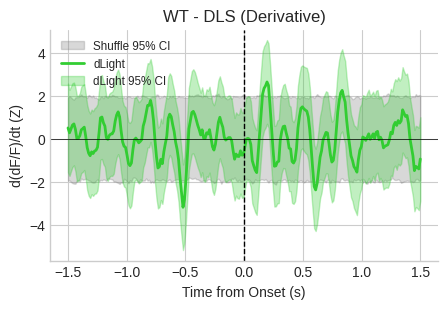

--- Analysis: WT DMS ---
Loading stats from cache: deriv_stats_WT_DMS.pkl


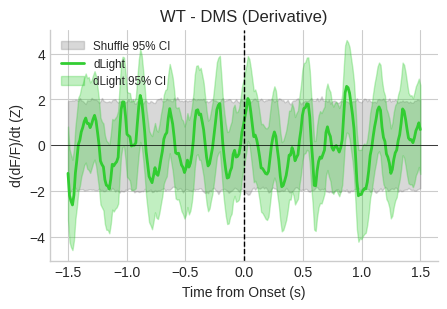

--- Analysis: WT VS ---
Loading stats from cache: deriv_stats_WT_VS.pkl


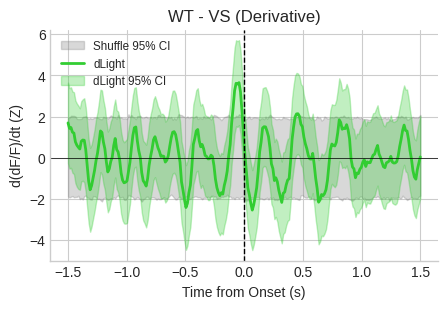

--- Analysis: KI DLS ---
Loading stats from cache: deriv_stats_KI_DLS.pkl


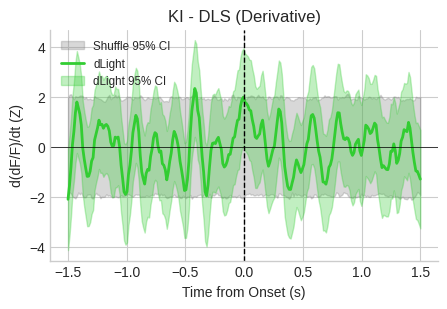

--- Analysis: KI DMS ---
Loading stats from cache: deriv_stats_KI_DMS.pkl


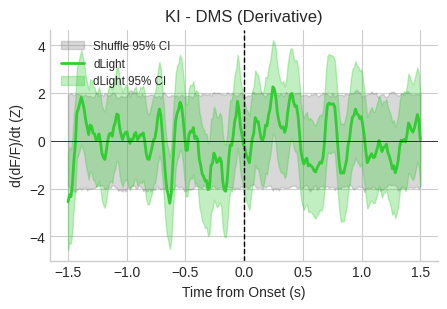

--- Analysis: KI VS ---
Loading stats from cache: deriv_stats_KI_VS.pkl


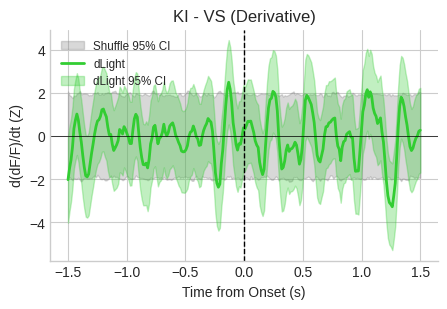

: 

In [ ]:
# Run
genotypes = ["WT", "KI"]
areas = ["DLS", "DMS", "VS"]

for geno in genotypes:
    for area in areas:
        run_deriv_analysis_jitter(sessions, geno, area, n_shuffles=1000)